In [1]:
import ast, os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from joblib import Parallel, delayed
from statsmodels.tsa.arima.model import ARIMA
from study_config import *

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

keys = ["window", "market_id", "commodity_id"]
panel = pd.read_csv(PROC / "forecast_panel.csv")
panel["per"] = pd.PeriodIndex(panel["ym"], freq="M")
train = panel[panel["role"] == "train"].sort_values("per")
test = panel[panel["role"] == "test"].copy()

# Seasonal Naive: observed value of the same month one year earlier. Naive: last training value.
test["ref"] = (test["per"] - 12).astype(str)
sn = train[keys + ["ym", "log_price"]].rename(columns={"ym": "ref", "log_price": "f_snaive"})
test = test.merge(sn, on=keys + ["ref"], how="left")
last = train.groupby(keys)["log_price"].last().rename("f_naive").reset_index()
test = test.merge(last, on=keys, how="left")
print("Test rows:", len(test), "| missing Seasonal Naive:", int(test["f_snaive"].isna().sum()),
      "| missing Naive:", int(test["f_naive"].isna().sum()))

Test rows: 49876 | missing Seasonal Naive: 0 | missing Naive: 0


In [2]:
CORE5 = CORE
EPS = 0.01          # PHP / percentage points, keeps ratios finite when a forecast is exact

def series_metrics(df, models):
    out = []
    for name, col in models.items():
        err = np.exp(df[col]) - df["price"]
        o = df.assign(ae=err.abs(), se=err ** 2, ape=err.abs() / df["price"])
        g = (o.groupby(keys + ["category", "commodity", "admin1"])
               .agg(n_test=("ae", "size"), MAE=("ae", "mean"),
                    RMSE=("se", lambda x: np.sqrt(x.mean())), MAPE=("ape", lambda x: x.mean() * 100)).reset_index())
        g["model"] = name
        out.append(g)
    return pd.concat(out, ignore_index=True)

def obs_errors(df, models):
    out = []
    for name, col in models.items():
        err = np.exp(df[col]) - df["price"]
        out.append(df.assign(model=name, ape=err.abs() / df["price"] * 100)[["window", "h", "model", "ape"]])
    return pd.concat(out, ignore_index=True)

def accuracy_tables(df, models):
    sm = series_metrics(df, models)
    obs = obs_errors(df, models)
    pooled = obs.groupby(["window", "model"])["ape"].agg(observations="size", pooled_MAPE="mean").round(2)
    pooled["median_series_MAPE"] = sm.groupby(["window", "model"])["MAPE"].median().round(2)
    obs["horizon"] = pd.cut(obs["h"], [0, 3, 6, 12], labels=["1-3", "4-6", "7-12"])
    bands = obs.groupby(["window", "horizon", "model"], observed=True)["ape"].mean().round(2).unstack("model")
    cats = sm.groupby(["window", "category", "model"])["MAPE"].median().round(2).unstack("model")
    core = (sm[sm["commodity"].isin(CORE5)].groupby(["commodity", "window", "model"])
              .agg(series=("MAE", "size"), MAE_PHP=("MAE", "median"), RMSE_PHP=("RMSE", "median"),
                   MAPE=("MAPE", "median")).round(2))
    return sm, pooled, bands, cats, core

def boot_ratio(df, B=1000, seed=42):
    rng = np.random.default_rng(seed)
    cl = df.groupby("market_id")["lr"].apply(lambda s: s.to_numpy())
    vals = [np.median(np.concatenate([cl.iloc[i] for i in rng.integers(0, len(cl), len(cl))])) for _ in range(B)]
    return np.exp(np.percentile(vals, [2.5, 97.5]))

def compare(sm, a, b):
    """Per series: ratio of model a's error to model b's (< 1 means a is better). CI resamples whole markets."""
    ma, mb = sm[sm["model"] == a].set_index(keys), sm[sm["model"] == b].set_index(keys)
    rows = []
    for w in WINDOWS:
        idx = [i for i in ma.index.intersection(mb.index) if i[0] == w]
        for metric in ["MAE", "RMSE", "MAPE"]:
            ra, rb = ma.loc[idx, metric], mb.loc[idx, metric]
            tmp = pd.DataFrame({"market_id": [i[1] for i in idx],
                                "lr": np.log(((ra + EPS) / (rb + EPS)).to_numpy())})
            lo, hi = boot_ratio(tmp)
            rows.append({"window": w, "metric": metric, "series": len(tmp),
                         f"{a}_better_%": round((ra.to_numpy() < rb.to_numpy()).mean() * 100, 1),
                         "ties_%": round((ra.to_numpy() == rb.to_numpy()).mean() * 100, 1),
                         "median_ratio": round(float(np.exp(tmp["lr"].median())), 2),
                         "ci_low": round(float(lo), 2), "ci_high": round(float(hi), 2),
                         "verdict": f"{a} better" if hi < 1 else (f"{b} better" if lo > 1 else "no clear winner")})
    return pd.DataFrame(rows)

def overall(cmp):
    return cmp.groupby("window")["verdict"].agg(lambda s: s.iloc[0] if s.nunique() == 1 else "mixed across metrics")

In [3]:
base_models = {"snaive": "f_snaive", "naive": "f_naive"}
sm_b, pooled_b, bands_b, cats_b, core_b = accuracy_tables(test, base_models)
print("Pooled MAPE (%) and median series MAPE:"); display(pooled_b)
print("\nMAPE (%) by horizon band:"); display(bands_b)
print("\nMedian series MAPE (%) by category:"); display(cats_b)
print("\nCore five commodities, Seasonal Naive (medians across series):"); display(core_b.xs("snaive", level="model"))
cmp_base = compare(sm_b, "naive", "snaive")
print("\nNaive vs Seasonal Naive:"); display(cmp_base)

Pooled MAPE (%) and median series MAPE:


observations  pooled_MAPE  median_series_MAPE
window        model                                                
Pandemic      naive          24060        12.08                8.22
              snaive         24060        14.72               11.82
Post-pandemic naive          24053        11.94                9.64
              snaive         24053        14.09               12.41
Pre-pandemic  naive           1763        10.10                7.29
              snaive          1763        12.88               10.76


MAPE (%) by horizon band:


model                  naive  snaive
window        horizon               
Pandemic      1-3       7.63   14.52
              4-6      11.54   15.38
              7-12     14.58   14.49
Post-pandemic 1-3       8.52   16.36
              4-6      12.39   14.11
              7-12     13.43   12.95
Pre-pandemic  1-3       7.42   13.63
              4-6      11.54   13.73
              7-12     10.66   12.09


Median series MAPE (%) by category:


model                                naive  snaive
window        category                            
Pandemic      cereals and tubers      2.50    3.87
              meat, fish and eggs     6.01    9.96
              pulses and nuts         5.08    6.86
              vegetables and fruits  14.43   17.68
Post-pandemic cereals and tubers      8.46   14.72
              meat, fish and eggs     5.32    7.41
              pulses and nuts         5.05    8.45
              vegetables and fruits  15.77   17.55
Pre-pandemic  cereals and tubers      8.28    8.93
              meat, fish and eggs     2.64    6.58
              vegetables and fruits  19.12   21.22


Core five commodities, Seasonal Naive (medians across series):


series  MAE_PHP  RMSE_PHP   MAPE
commodity                     window                                         
Meat (beef, chops with bones) Pandemic           67    33.85     36.67   9.64
                              Post-pandemic      67    21.72     24.71   5.73
                              Pre-pandemic       15    17.69     21.43   7.54
Meat (chicken, whole)         Pandemic           59    26.18     27.73  12.84
                              Post-pandemic      59     9.54     11.93   4.73
                              Pre-pandemic       16     7.86      9.87   4.76
Meat (pork)                   Pandemic           63    26.49     30.36   8.64
                              Post-pandemic      63    30.21     36.52   9.01
                              Pre-pandemic       17     9.53     11.84   4.09
Onions (red)                  Pandemic           56    85.92    116.23  34.39
                              Post-pandemic      56    40.57     51.84  23.11
                              Pre-pandemic       16    19.23     24.01  23.94
Rice (regular, milled)        Pandemic           74     1.43      1.71   3.79
                              Post-pandemic      74     8.07      8.91  18.97
                              Pre-pandemic       11     3.59      4.09   8.56


Naive vs Seasonal Naive:


,window,metric,series,naive_better_%,ties_%,median_ratio,ci_low,ci_high,verdict
0,Pre-pandemic,MAE,153,73.2,1.3,0.71,0.66,0.79,naive better
1,Pre-pandemic,RMSE,153,75.8,1.3,0.76,0.69,0.82,naive better
2,Pre-pandemic,MAPE,153,75.2,1.3,0.72,0.66,0.80,naive better
3,Pandemic,MAE,2005,71.1,0.3,0.76,0.74,0.79,naive better
4,Pandemic,RMSE,2005,70.9,0.3,0.80,0.78,0.83,naive better
5,Pandemic,MAPE,2005,71.7,0.3,0.75,0.73,0.78,naive better
6,Post-pandemic,MAE,2005,68.1,0.3,0.81,0.79,0.83,naive better
7,Post-pandemic,RMSE,2005,66.9,0.3,0.85,0.83,0.87,naive better
8,Post-pandemic,MAPE,2005,69.8,0.3,0.80,0.78,0.82,naive better


In [4]:
train_arrays = train.groupby(keys)["log_price"].apply(lambda s: s.to_numpy())
GRID = [(p, q, P, Q) for p in (0, 1) for q in (0, 1) for (P, Q) in ((0, 0), (1, 0), (0, 1))]   # 12 candidate models
MAX_JUMP = 2.0      # stability screen: a forecast more than 2 log points (about x7) from the last value is rejected

def fit_sarima_auto(y, steps=12):
    best, spec = None, None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for p, q, P, Q in GRID:
            try:
                m = ARIMA(y, order=(p, 1, q), seasonal_order=(P, 0, Q, 12), trend="n").fit()
            except Exception:
                continue
            if np.isfinite(m.aic) and (best is None or m.aic < best.aic):
                best, spec = m, (p, q, P, Q)
        if best is None:
            return None, None, "no model converged"
        fc = np.asarray(best.forecast(steps), dtype=float)
    if not np.isfinite(fc).all():
        return None, None, "non-finite forecast"
    if np.abs(fc - y[-1]).max() > MAX_JUMP:
        return None, None, "unstable forecast"
    return fc, spec, ""

def run_one(key, y):
    fc, spec, why = fit_sarima_auto(y)
    return key, fc, spec, why

In [5]:
cores = os.cpu_count() or 2
sample = random.Random(1).sample(list(train_arrays.items()), 30)
t0 = time.time()
res = [run_one(k, y) for k, y in sample]
dt = (time.time() - t0) / len(sample)
n_all = len(train_arrays)
print(f"Pilot: {dt:.2f} s per series-window | failures: {sum(r[1] is None for r in res)} of {len(res)}")
print(f"Full run of {n_all} series-windows: about {dt * n_all / 3600:.1f} h on one core, "
      f"about {dt * n_all / 3600 / max(1, cores - 1):.1f} h with {max(1, cores - 1)} workers")

Pilot: 1.59 s per series-window | failures: 0 of 30
Full run of 4163 series-windows: about 1.8 h on one core, about 0.2 h with 11 workers


In [6]:
OUT = PROC / "sarima"; OUT.mkdir(exist_ok=True)
N_JOBS = -2          # all cores but one
BATCH = 200
LIMIT = None         # set to 50 for a quick trial run

def run_window(w, limit=None):
    f = OUT / f"sarima_{w}.csv"
    done = set()
    if f.exists():
        prev = pd.read_csv(f)
        done = set(zip(prev["market_id"], prev["commodity_id"]))
    todo = [(k, y) for k, y in train_arrays.items() if k[0] == w and (k[1], k[2]) not in done]
    if limit:
        todo = todo[:limit]
    for i in range(0, len(todo), BATCH):
        batch = todo[i:i + BATCH]
        res = Parallel(n_jobs=N_JOBS)(delayed(run_one)(k, y) for k, y in batch)
        rows = []
        for k, fc, spec, why in res:
            r = {"window": k[0], "market_id": k[1], "commodity_id": k[2],
                 "spec": str(spec) if spec else "", "fail_reason": why}
            for s in range(12):
                r[f"fc{s + 1}"] = fc[s] if fc is not None else np.nan
            rows.append(r)
        pd.DataFrame(rows).to_csv(f, mode="a", header=not f.exists(), index=False)
        print(f"{w}: {min(i + BATCH, len(todo))}/{len(todo)} done")

for w in WINDOWS:
    run_window(w, LIMIT)

In [7]:
sar = pd.concat([pd.read_csv(OUT / f"sarima_{w}.csv") for w in WINDOWS], ignore_index=True)
sar["fail_reason"] = sar["fail_reason"].fillna("")
print("SARIMA fits:", len(sar), "of", n_all)
display(sar.assign(failed=sar["fail_reason"] != "").groupby("window")["failed"].agg(["sum", "mean"]).round(3))
print("Failure reasons:", sar[sar["fail_reason"] != ""]["fail_reason"].value_counts().to_dict())

good = sar[sar["fail_reason"] == ""].copy()
good["seasonal_terms"] = good["spec"].map(lambda s: sum(ast.literal_eval(s)[2:]) > 0)
print("Share of fitted series where AIC chose seasonal terms:", good.groupby("window")["seasonal_terms"].mean().round(2).to_dict())

sar_long = sar.melt(id_vars=keys, value_vars=[f"fc{s}" for s in range(1, 13)], var_name="h", value_name="f_sarima")
sar_long["h"] = sar_long["h"].str[2:].astype(int)
test_all = test.merge(sar_long, on=keys + ["h"], how="left")
paired = test_all.merge(good[keys], on=keys)           # only series where SARIMA produced a usable forecast
print("Paired series-windows:", paired.groupby(keys).ngroups, "| test observations:", len(paired))

SARIMA fits: 4163 of 4163


,sum,mean
window,,
Pandemic,1,0.0
Post-pandemic,0,0.0
Pre-pandemic,0,0.0


Failure reasons: {'unstable forecast': 1}
Share of fitted series where AIC chose seasonal terms: {'Pandemic': 0.21, 'Post-pandemic': 0.32, 'Pre-pandemic': 0.16}
Paired series-windows: 4162 | test observations: 49864


In [8]:
all_models = {"snaive": "f_snaive", "naive": "f_naive", "sarima": "f_sarima"}
sm, pooled, bands, cats, core = accuracy_tables(paired, all_models)
print("Pooled MAPE (%) and median series MAPE:"); display(pooled)
print("\nMAPE (%) by horizon band:"); display(bands)
print("\nMedian series MAPE (%) by category:"); display(cats)
print("\nCore five, SARIMA:"); display(core.xs("sarima", level="model"))
print("\nCore five, Seasonal Naive:"); display(core.xs("snaive", level="model"))

chk = pd.concat([pooled_b["pooled_MAPE"].rename("all eligible series"),
                 pooled["pooled_MAPE"].rename("paired set")], axis=1).dropna()
print("\nSelection check (baseline pooled MAPE on all eligible series vs the paired set):"); display(chk)

cmp_main = compare(sm, "sarima", "snaive")
cmp_naive = compare(sm, "sarima", "naive")
print("\nPRIMARY: SARIMA vs Seasonal Naive"); display(cmp_main)
print("Overall verdict per window (all three metrics must agree):"); display(overall(cmp_main))
print("\nSUPPLEMENTARY: SARIMA vs Naive"); display(cmp_naive)
print("Overall verdict per window:"); display(overall(cmp_naive))

Pooled MAPE (%) and median series MAPE:


observations  pooled_MAPE  median_series_MAPE
window        model                                                
Pandemic      naive          24048        12.08                8.22
              sarima         24048        12.68                8.64
              snaive         24048        14.70               11.81
Post-pandemic naive          24053        11.94                9.64
              sarima         24053        11.82                9.81
              snaive         24053        14.09               12.41
Pre-pandemic  naive           1763        10.10                7.29
              sarima          1763        10.19                7.80
              snaive          1763        12.88               10.76


MAPE (%) by horizon band:


model                  naive  sarima  snaive
window        horizon                       
Pandemic      1-3       7.63    8.13   14.48
              4-6      11.54   12.03   15.35
              7-12     14.58   15.28   14.48
Post-pandemic 1-3       8.52    8.34   16.36
              4-6      12.39   11.89   14.11
              7-12     13.43   13.52   12.95
Pre-pandemic  1-3       7.42    7.29   13.63
              4-6      11.54   11.35   13.73
              7-12     10.66   10.98   12.09


Median series MAPE (%) by category:


model                                naive  sarima  snaive
window        category                                    
Pandemic      cereals and tubers      2.50    2.83    3.87
              meat, fish and eggs     6.01    6.31    9.96
              pulses and nuts         5.08    5.15    6.86
              vegetables and fruits  14.43   14.81   17.68
Post-pandemic cereals and tubers      8.46    8.66   14.72
              meat, fish and eggs     5.32    5.47    7.41
              pulses and nuts         5.05    5.62    8.45
              vegetables and fruits  15.77   15.64   17.55
Pre-pandemic  cereals and tubers      8.28    8.63    8.93
              meat, fish and eggs     2.64    2.83    6.58
              vegetables and fruits  19.12   17.49   21.22

... (10 outputs left out)


SUPPLEMENTARY: SARIMA vs Naive


,window,metric,series,sarima_better_%,ties_%,median_ratio,ci_low,ci_high,verdict
0,Pre-pandemic,MAE,153,24.8,43.8,1.0,1.0,1.0,no clear winner
1,Pre-pandemic,RMSE,153,24.8,43.8,1.0,1.0,1.0,no clear winner
2,Pre-pandemic,MAPE,153,24.8,43.8,1.0,1.0,1.0,no clear winner
3,Pandemic,MAE,2004,20.3,52.3,1.0,1.0,1.0,no clear winner
4,Pandemic,RMSE,2004,20.2,52.0,1.0,1.0,1.0,no clear winner
5,Pandemic,MAPE,2004,20.2,52.0,1.0,1.0,1.0,no clear winner
6,Post-pandemic,MAE,2005,32.6,34.2,1.0,1.0,1.0,no clear winner
7,Post-pandemic,RMSE,2005,34.0,33.5,1.0,1.0,1.0,no clear winner
8,Post-pandemic,MAPE,2005,33.2,33.5,1.0,1.0,1.0,no clear winner


Overall verdict per window:


window
Pandemic         no clear winner
Post-pandemic    no clear winner
Pre-pandemic     no clear winner
Name: verdict, dtype: str

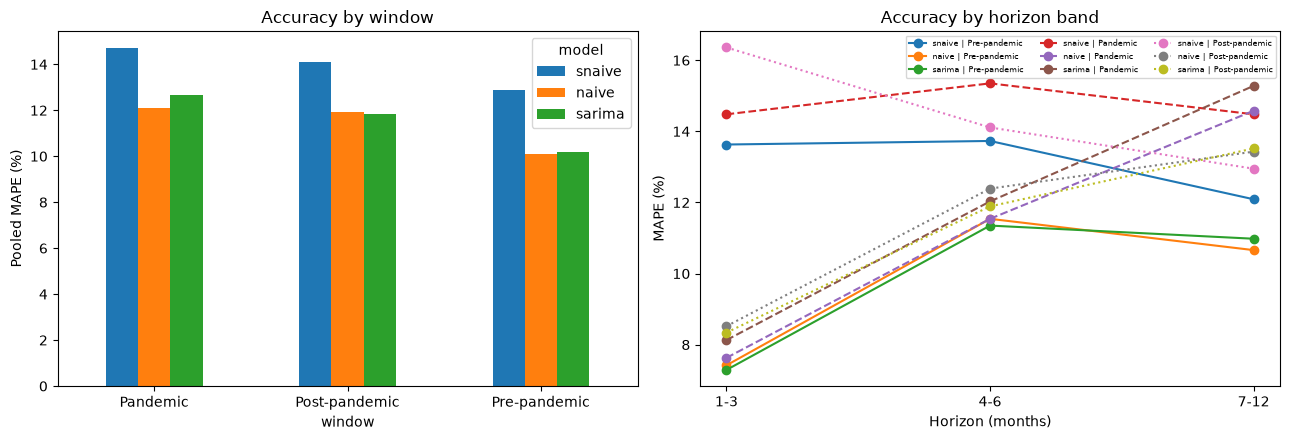

saved


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pooled["pooled_MAPE"].unstack("model")[["snaive", "naive", "sarima"]].plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("Pooled MAPE (%)"); axes[0].set_title("Accuracy by window"); axes[0].tick_params(axis="x", rotation=0)
for w, ls in zip(WINDOWS, ["-", "--", ":"]):
    b = bands.xs(w, level="window")
    for m in ["snaive", "naive", "sarima"]:
        axes[1].plot(b.index.astype(str), b[m], ls=ls, marker="o", label=f"{m} | {w}")
axes[1].set_ylabel("MAPE (%)"); axes[1].set_xlabel("Horizon (months)"); axes[1].set_title("Accuracy by horizon band")
axes[1].legend(fontsize=6, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "12_accuracy.png", dpi=150); plt.show()

sar.to_csv(TAB / "12_sarima_fit_log.csv", index=False)
sm.to_csv(TAB / "12_series_metrics.csv", index=False)
pooled.to_csv(TAB / "12_accuracy_by_window.csv"); bands.to_csv(TAB / "12_accuracy_by_horizon.csv")
cats.to_csv(TAB / "12_accuracy_by_category.csv"); core.to_csv(TAB / "12_accuracy_core_five.csv")
cmp_main.to_csv(TAB / "12_sarima_vs_snaive.csv", index=False)
cmp_naive.to_csv(TAB / "12_sarima_vs_naive.csv", index=False)
cmp_base.to_csv(TAB / "12_naive_vs_snaive.csv", index=False)
paired.to_csv(PROC / "forecast_results_paired.csv", index=False)
print("saved")

In [10]:
good["is_random_walk"] = good["spec"].eq("(0, 0, 0, 0)")      # ARIMA(0,1,0), no seasonal terms = Naive forecast
print("Share of fitted series where AIC chose the random walk:",
      good.groupby("window")["is_random_walk"].mean().round(3).to_dict())
print("Most common specifications (p, q, P, Q):")
print(good["spec"].value_counts().head(6).to_string())

Share of fitted series where AIC chose the random walk: {'Pandemic': 0.51, 'Post-pandemic': 0.321, 'Pre-pandemic': 0.431}
Most common specifications (p, q, P, Q):
spec
(0, 0, 0, 0)    1733
(0, 1, 0, 0)     612
(0, 0, 1, 0)     430
(1, 1, 0, 0)     413
(1, 0, 0, 0)     314
(1, 1, 1, 0)     150


In [11]:
def boot_mean(df, col, B=1000, seed=42):
    rng = np.random.default_rng(seed)
    cl = df.groupby("market_id")[col].apply(lambda s: s.to_numpy())
    vals = [np.mean(np.concatenate([cl.iloc[i] for i in rng.integers(0, len(cl), len(cl))])) for _ in range(B)]
    return np.exp(np.percentile(vals, [2.5, 97.5]))

def compare_gm(sm, a, b):
    ma, mb = sm[sm["model"] == a].set_index(keys), sm[sm["model"] == b].set_index(keys)
    rows = []
    for w in WINDOWS:
        idx = [i for i in ma.index.intersection(mb.index) if i[0] == w]
        for metric in ["MAE", "RMSE", "MAPE"]:
            ra, rb = ma.loc[idx, metric].to_numpy(), mb.loc[idx, metric].to_numpy()
            df = pd.DataFrame({"market_id": [i[1] for i in idx], "lr": np.log((ra + EPS) / (rb + EPS)), "tie": ra == rb})
            nt = df[~df["tie"]]
            lo, hi = boot_mean(df, "lr")
            lo2, hi2 = boot_mean(nt, "lr")
            rows.append({"window": w, "metric": metric, "series": len(df), "ties_%": round(df["tie"].mean() * 100, 1),
                         "gm_ratio_all": round(float(np.exp(df["lr"].mean())), 3), "ci_all": f"{lo:.3f}-{hi:.3f}",
                         "non_tied": len(nt), f"{a}_better_%_of_non_tied": round((nt["lr"] < 0).mean() * 100, 1),
                         "gm_ratio_non_tied": round(float(np.exp(nt["lr"].mean())), 3), "ci_non_tied": f"{lo2:.3f}-{hi2:.3f}",
                         "verdict_all": f"{a} better" if hi < 1 else (f"{b} better" if lo > 1 else "no clear winner")})
    return pd.DataFrame(rows)

cmp_gm = compare_gm(sm, "sarima", "naive")
print("SARIMA vs Naive (geometric-mean error ratio; < 1 favours SARIMA):"); display(cmp_gm)
print("Overall verdict per window:"); display(overall(cmp_gm.rename(columns={"verdict_all": "verdict"})))

nonrw = good[~good["is_random_walk"]][keys]
p2 = paired.merge(nonrw, on=keys)
b2 = obs_errors(p2, {"naive": "f_naive", "sarima": "f_sarima"})
b2["horizon"] = pd.cut(b2["h"], [0, 3, 6, 12], labels=["1-3", "4-6", "7-12"])
print("\nMAPE (%) by horizon band, only series where SARIMA is NOT the random walk:")
display(b2.groupby(["window", "horizon", "model"], observed=True)["ape"].mean().round(2).unstack("model"))
cmp_gm.to_csv(TAB / "12B_sarima_vs_naive_tie_robust.csv", index=False)

SARIMA vs Naive (geometric-mean error ratio; < 1 favours SARIMA):


,window,metric,series,ties_%,gm_ratio_all,ci_all,non_tied,sarima_better_%_of_non_tied,gm_ratio_non_tied,ci_non_tied,verdict_all
0,Pre-pandemic,MAE,153,43.8,1.061,0.999-1.181,86,44.2,1.110,0.998-1.346,no clear winner
1,Pre-pandemic,RMSE,153,43.8,1.058,1.000-1.177,86,44.2,1.106,1.000-1.339,no clear winner
2,Pre-pandemic,MAPE,153,43.8,1.058,1.000-1.166,86,44.2,1.106,1.000-1.313,naive better
3,Pandemic,MAE,2004,52.3,1.057,1.040-1.075,956,42.6,1.124,1.087-1.165,naive better
4,Pandemic,RMSE,2004,52.0,1.054,1.038-1.071,961,42.0,1.115,1.080-1.154,naive better
5,Pandemic,MAPE,2004,52.0,1.059,1.043-1.077,961,42.1,1.128,1.090-1.168,naive better
6,Post-pandemic,MAE,2005,34.2,1.007,0.995-1.021,1320,49.5,1.011,0.992-1.033,no clear winner
7,Post-pandemic,RMSE,2005,33.5,1.009,0.996-1.022,1334,51.1,1.013,0.994-1.033,no clear winner
8,Post-pandemic,MAPE,2005,33.5,1.009,0.996-1.023,1334,49.9,1.013,0.994-1.036,no clear winner


Overall verdict per window:


window
Pandemic                 naive better
Post-pandemic         no clear winner
Pre-pandemic     mixed across metrics
Name: verdict, dtype: str


MAPE (%) by horizon band, only series where SARIMA is NOT the random walk:


model                  naive  sarima
window        horizon               
Pandemic      1-3       8.02    9.03
              4-6      11.50   12.49
              7-12     15.78   17.21
Post-pandemic 1-3       9.44    9.17
              4-6      13.72   12.99
              7-12     14.34   14.48
Pre-pandemic  1-3       8.04    7.81
              4-6      12.47   12.13
              7-12     11.10   11.67